In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

column_types = {
    "id": "Int64",
    "osm_id": "str",
    "object_id": "str",
    "addr_street": "str",
    "addr_number": "str",
    "ground_floor_group": "str",
    "ground_floor_function": "str",
    "upper_floor_group": "str",
    "upper_floor_function": "str",
    "number_of_storeys": "Int64",
    "is_mixed_use": "boolean",
    "build_year_est": "Int64",
    "arch_style": "str",
    "condition": "Int64",
    "max_height": "float64",
    "is_heritage": "str",
    "source": "str",
    "confidence": "Int64",
    "date_of_checking": "str",
    "number_of_functions": "Int64",
}


In [2]:
data_gdynia = pd.read_csv(
    "../../data/processed/fixed/srodmiescie.csv",
    sep=";",
    index_col=0,
    dtype=column_types,
    parse_dates=["date_of_checking"],
)

In [3]:
data_gdynia_long_categories = pd.read_csv(
    "../../data/processed/fixed/srodmiescie_long_categories.csv",
    sep=";",
    index_col=0,
    dtype=column_types,
)

In [4]:
data_gdynia.resample("W", on="date_of_checking").size()

date_of_checking
2026-09-27    788
2026-10-04    194
Freq: W-SUN, dtype: int64

In [5]:
REF = pd.Timestamp("2026-10-17")

data_gdynia = data_gdynia.assign(
    days_since_checking=lambda d: (REF - d["date_of_checking"]).dt.days
)
data_gdynia.loc[data_gdynia["days_since_checking"] >= 21]

,osm_id,addr_street,addr_number,ground_floor_group,ground_floor_function,upper_floor_group,upper_floor_function,number_of_storeys,is_mixed_use,build_year_est,arch_style,condition,max_height,is_heritage,source,confidence,date_of_checking,number_of_functions,days_since_checking
id,,,,,,,,,,,,,,,,,,,
50,126901824,Stefana Żeromskiego,5,NaN,mieszkaniowa jednorodzinna,NaN,mieszkaniowa jednorodzinna,2,<NA>,1980,współczesność,2,NaN,NaN,google.com/maps,2,2026-09-26,1,21
51,126901815,Portowa,4,NaN,"fryzjer,masaż,siłownia,psycholog",NaN,mieszkaniowa jednorodzinna,5,<NA>,1930,modernizm,2,NaN,NaN,google.com/maps,2,2026-09-26,4,21
55,127110169,Jerzego Waszyngtona,5,NaN,mieszkaniowa jednorodzinna,NaN,mieszkaniowa jednorodzinna,2,<NA>,1980,współczesność,2,NaN,NaN,google.com/maps,2,2026-09-26,1,21
96,398139549,NaN,NaN,NaN,garaż,NaN,NaN,1,<NA>,1980,współczesność,2,NaN,NaN,google.com/maps,3,2026-09-26,1,21
106,1226355010,Portowa,NaN,NaN,restauracja,NaN,NaN,1,<NA>,1980,współczesność,2,NaN,NaN,google.com/maps,3,2026-09-26,1,21
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
936,183360059,NaN,NaN,NaN,techniczne,NaN,NaN,1,<NA>,2000,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-26,1,21
937,183360062,NaN,NaN,NaN,garaż,NaN,NaN,1,<NA>,1980,współczesność,2,NaN,NaN,google.com/maps,3,2026-09-26,1,21
938,183360061,NaN,NaN,NaN,garaż,NaN,NaN,1,<NA>,1980,współczesność,2,NaN,NaN,google.com/maps,3,2026-09-26,1,21


In [6]:
assert len(data_gdynia.loc[data_gdynia["days_since_checking"] >= 21]) == 327
assert data_gdynia["date_of_checking"].dtype == "<M8[us]"

1.

In [ ]:
buildings_per_dates = (
    data_gdynia.resample("D", on="date_of_checking")
    .size()
    .reset_index(name="num_build")
)

premises_per_dates = (
    data_gdynia_long_categories.join(data_gdynia, rsuffix="r")
    .loc[:, ["addr_street", "date_of_checking"]]
    .resample("D", on="date_of_checking")
    .size()
    .reset_index(name="num_premises")
)

summary_date_buildings_premises = pd.merge(
    buildings_per_dates, premises_per_dates, on="date_of_checking"
).set_index("date_of_checking")
summary_date_buildings_premises

,num_build,num_premises
date_of_checking,,
2026-09-23,52,73
2026-09-24,108,141
2026-09-25,67,85
2026-09-26,100,138
2026-09-27,461,594
2026-09-28,0,0
2026-09-29,22,38
2026-09-30,172,281


In [ ]:
assert (summary_date_buildings_premises.loc["2026-09-27"] == [461, 594]).all()
assert (summary_date_buildings_premises.sum(axis=0) == [982, 1350]).all()

summary_date_buildings_premises_w = summary_date_buildings_premises.resample("W").sum()
assert (summary_date_buildings_premises_w.iloc[0] == [788, 1031]).all()
assert (summary_date_buildings_premises_w.iloc[1] == [194, 319]).all()

2.

In [ ]:
REF = pd.to_datetime("18-10-2026", dayfirst=True)

In [ ]:
data_gdynia_dates = (
    data_gdynia.groupby("addr_street")
    .agg(num_build=("osm_id", "size"), date_last=("date_of_checking", "max"))
    .assign(days_since_checking=lambda d: (REF - d["date_last"]).dt.days)
)
data_gdynia_first_checked = data_gdynia_dates.loc[
    data_gdynia_dates["days_since_checking"] >= 23
].sort_values(["days_since_checking", "num_build"], ascending=False)

data_gdynia_first_checked

,num_build,date_last,days_since_checking
addr_street,,,
Zgoda,11,2026-09-24,24
Mściwoja,10,2026-09-24,24
Szkolna,1,2026-09-24,24
Hilarego Jastaka,1,2026-09-25,23


In [ ]:
assert (
    data_gdynia_first_checked.index
    == ["Zgoda", "Mściwoja", "Szkolna", "Hilarego Jastaka"]
).all()

3.

In [12]:
summary_date_buildings_premises

,num_build,num_premises
date_of_checking,,
2026-09-23,52,73
2026-09-24,108,141
2026-09-25,67,85
2026-09-26,100,138
2026-09-27,461,594
2026-09-28,0,0
2026-09-29,22,38
2026-09-30,172,281


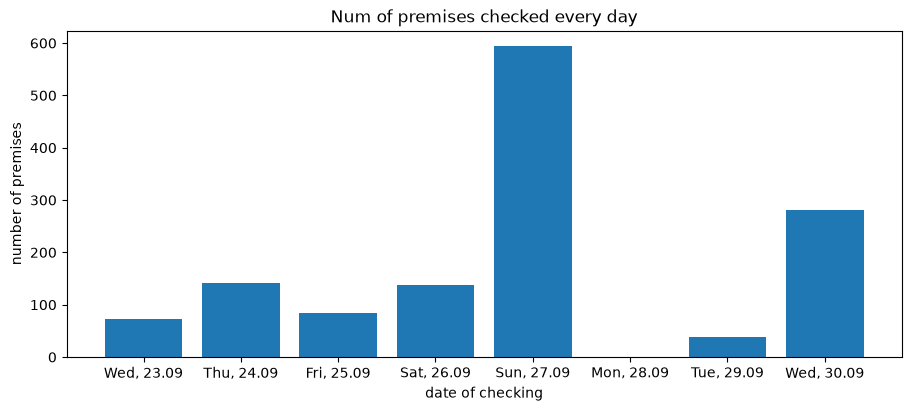

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")

ax.bar(
    summary_date_buildings_premises.index.strftime("%a, %d.%m"),
    summary_date_buildings_premises["num_premises"],
)

ax.set_title("Num of premises checked every day")
ax.set_xlabel("date of checking")
ax.set_ylabel("number of premises")

plt.show()